# DSCI 552 — Homework 6
**Zexin Xiong · GitHub: zexinxiong**

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
DATA = ROOT / 'data'
RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)
SEED = 552

def load_aps(path):
    frame = pd.read_csv(path, skiprows=20, na_values=['na'])
    y = frame.pop('class').eq('pos').astype(np.int8).to_numpy()
    return frame.astype('float32'), y

X_train_raw, y_train = load_aps(DATA / 'aps_failure_training_set.csv.gz')
X_test_raw, y_test = load_aps(DATA / 'aps_failure_test_set.csv.gz')
assert X_train_raw.shape == (60000, 170) and X_test_raw.shape == (16000, 170)
assert X_train_raw.columns.equals(X_test_raw.columns)
print('Training:', X_train_raw.shape, 'Test:', X_test_raw.shape)
print('Class counts:', np.bincount(y_train), np.bincount(y_test))

Training: (60000, 170) Test: (16000, 170)
Class counts: [59000  1000] [15625   375]


## 1(a–b)(i). Data and missing values

Common approaches include deleting incomplete rows or columns, filling with a constant, mean or median, nearest-neighbor imputation, and model-based iterative imputation. Deleting rows here would discard many observations; iterative methods are expensive at 170 dimensions. I use the **training-column median** for each missing feature, fitted only on training rows and reused for the held-out test set. In cross-validation it is refitted inside each training fold to avoid leakage. This is a simple, robust baseline for skewed numeric measurements.

In [2]:
missing = X_train_raw.isna().sum().sort_values(ascending=False)
print('Missing training cells:', int(missing.sum()), 'of', X_train_raw.size)
print('Rows with missing values:', int(X_train_raw.isna().any(axis=1).sum()))
print('Most missing features:')
display(missing.head(10).to_frame('missing'))
imputer = SimpleImputer(strategy='median', keep_empty_features=True)
X_train = imputer.fit_transform(X_train_raw).astype('float32')
X_test = imputer.transform(X_test_raw).astype('float32')
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()

Missing training cells: 850015 of 10200000
Rows with missing values: 59409
Most missing features:


,missing
br_000,49264
bq_000,48722
bp_000,47740
bo_000,46333
cr_000,46329
ab_000,46329
bn_000,44009
bm_000,39549
bl_000,27277
bk_000,23034


## 1(b)(ii–v). Variation, correlation, selected plots, imbalance

The coefficient of variation uses sample SD (`ddof=1`) divided by sample mean. Undefined ratios for zero means are recorded as missing. The 13 largest finite CVs are shown only for exploratory plots; **all 170 features** enter the models. Scatterplots can suggest patterns, but cannot establish statistical significance without a model and uncertainty analysis.

Top 13 CV features:


,0
cf_000,244.887512
co_000,244.507370
ad_000,244.322815
cs_009,237.930573
dh_000,123.216103
dj_000,117.494232
ag_000,92.917755
as_000,87.332504
ay_009,84.733734
ak_000,80.424973


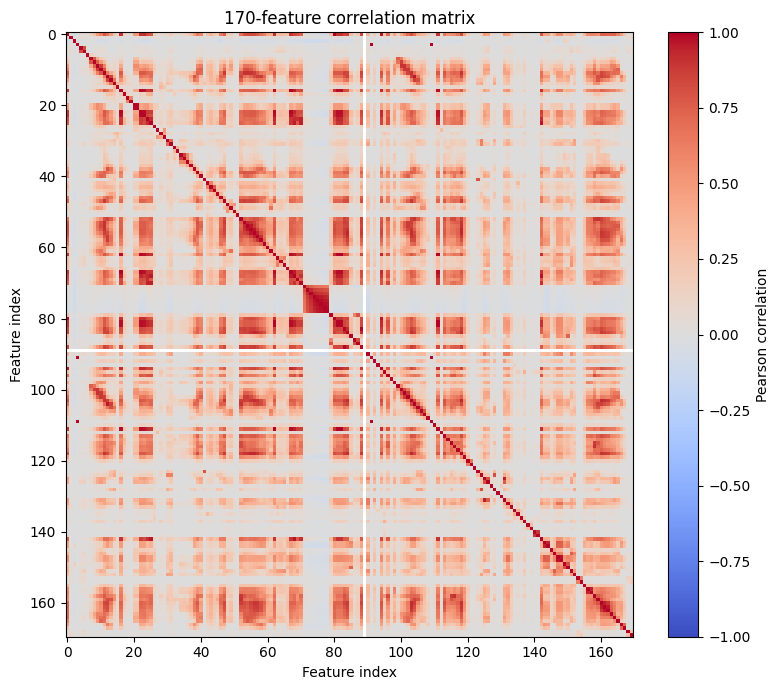

Positive: 1,000; negative: 59,000; positive share: 1.67%


In [3]:
train_df = pd.DataFrame(X_train, columns=X_train_raw.columns)
means = train_df.mean()
cv = (train_df.std(ddof=1) / means.replace(0, np.nan)).replace([np.inf, -np.inf], np.nan)
cv.rename('CV').to_csv(RESULTS / 'coefficient_of_variation.csv')
top = cv.nlargest(13).index.tolist()
print('Top 13 CV features:')
display(cv.loc[top].to_frame())
cor = train_df.corr()
cor.to_csv(RESULTS / 'correlation_matrix.csv')
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cor, vmin=-1, vmax=1, cmap='coolwarm', aspect='auto')
fig.colorbar(im, ax=ax, label='Pearson correlation')
ax.set(title='170-feature correlation matrix', xlabel='Feature index', ylabel='Feature index')
fig.tight_layout(); fig.savefig(RESULTS / 'correlation_matrix.png', dpi=130); plt.show()
print(f'Positive: {y_train.sum():,}; negative: {(1-y_train).sum():,}; positive share: {y_train.mean():.2%}')

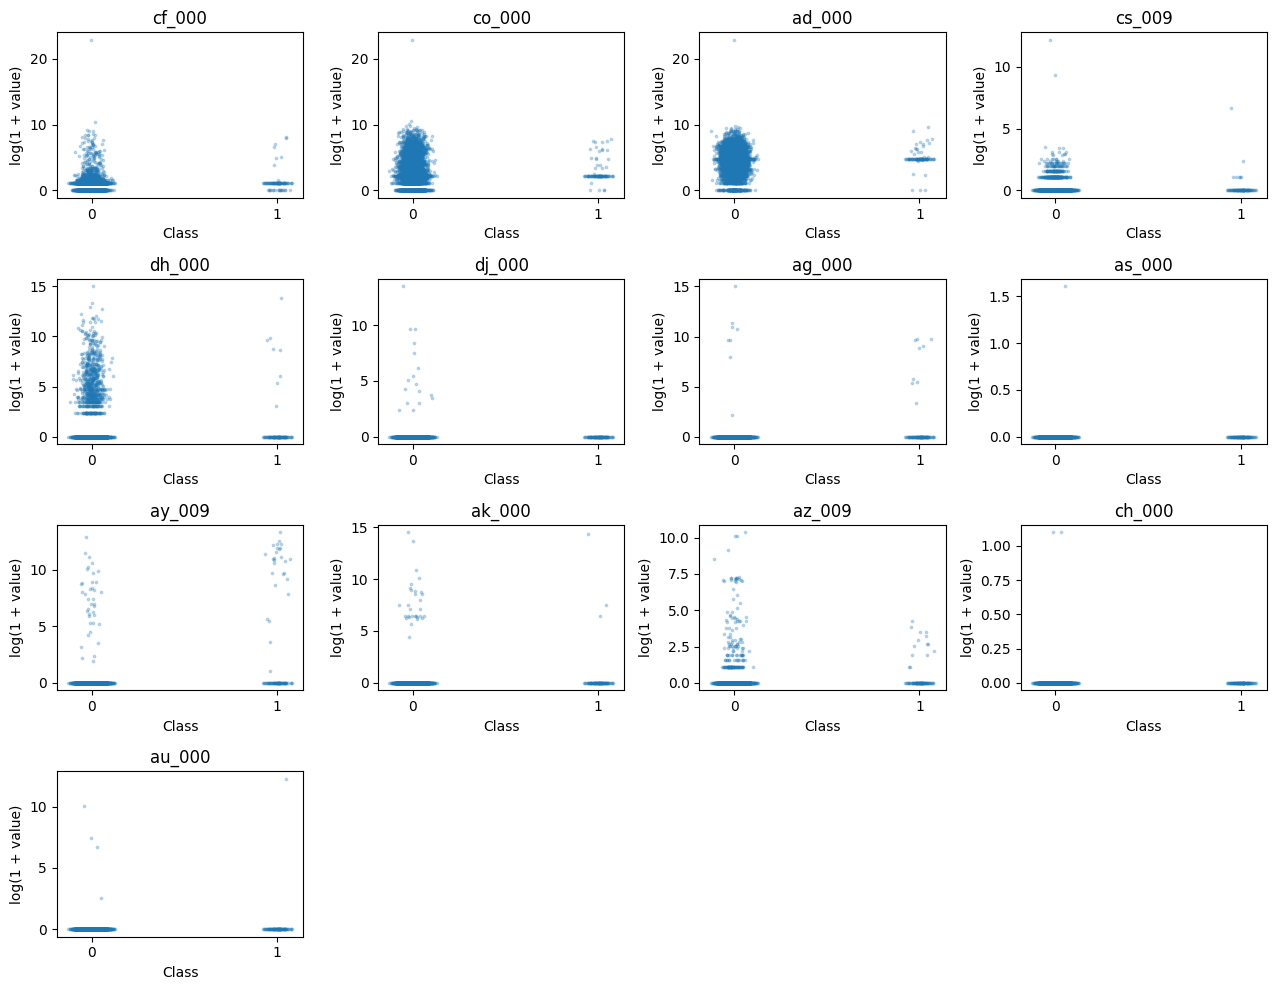

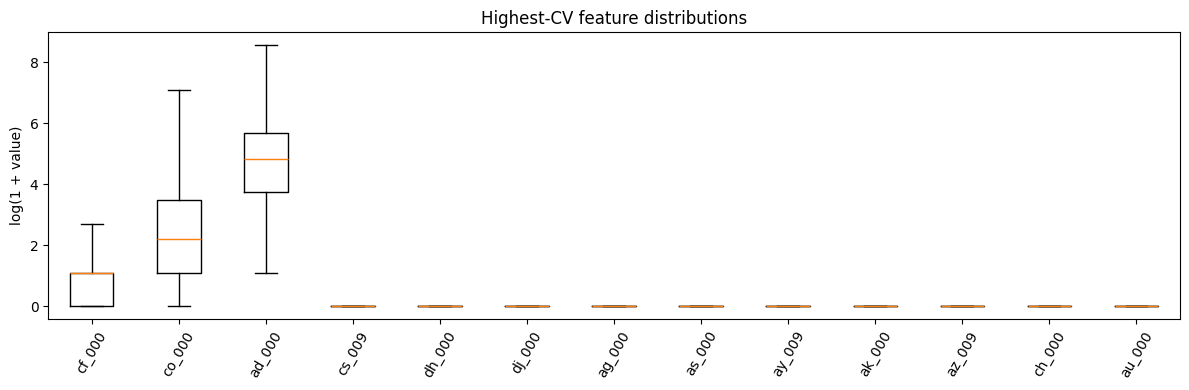

In [4]:
fig, axes = plt.subplots(4, 4, figsize=(13, 10))
sample = np.random.default_rng(SEED).choice(len(y_train), size=6000, replace=False)
for ax, name in zip(axes.flat, top):
    ax.scatter(y_train[sample] + np.random.default_rng(SEED).normal(0, .035, len(sample)),
               np.log1p(np.maximum(train_df[name].to_numpy()[sample], 0)), s=3, alpha=.25)
    ax.set(title=name, xticks=[0, 1], xlabel='Class', ylabel='log(1 + value)')
for ax in axes.flat[len(top):]: ax.axis('off')
fig.tight_layout(); fig.savefig(RESULTS / 'top_cv_scatter.png', dpi=120); plt.show()
fig, ax = plt.subplots(figsize=(12, 4))
ax.boxplot([np.log1p(np.maximum(train_df[c].to_numpy(), 0)) for c in top], tick_labels=top, showfliers=False)
ax.set(ylabel='log(1 + value)', title='Highest-CV feature distributions')
ax.tick_params(axis='x', rotation=60)
fig.tight_layout(); fig.savefig(RESULTS / 'top_cv_boxplots.png', dpi=120); plt.show()

## 1(c–d). Random forest without and with imbalance compensation

The first forest uses ordinary bootstrap samples and no class weighting. The second uses inverse-frequency `class_weight='balanced_subsample'`, computed within each bootstrap sample. The out-of-bag error is `1 - oob_score_`; it estimates ordinary classification error, not minority recall. Each forest is assessed on its training and untouched test sets.

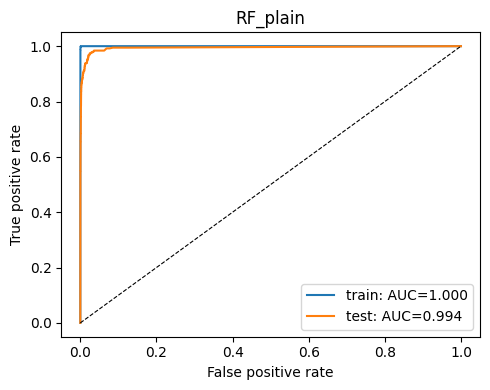

,model,split,error,AUC,TN,FP,FN,TP
0,RF_plain,train,0.001083,0.999991,59000,0,65,935
1,RF_plain,test,0.008375,0.994188,15607,18,116,259


Unweighted OOB error: 0.006449999999999956 held-out test error: 0.008375000000000021


In [5]:
def evaluate(name, model, xtr, xte, ytr=y_train, yte=y_test):
    rows = []
    fig, ax = plt.subplots(figsize=(5, 4))
    for split, x, y in [('train', xtr, ytr), ('test', xte, yte)]:
        pred = model.predict(x)
        prob = model.predict_proba(x)[:, 1]
        cm = confusion_matrix(y, pred)
        fpr, tpr, _ = roc_curve(y, prob)
        auc = roc_auc_score(y, prob)
        error = 1 - accuracy_score(y, pred)
        rows.append(dict(model=name, split=split, error=error, AUC=auc,
                         TN=cm[0,0], FP=cm[0,1], FN=cm[1,0], TP=cm[1,1]))
        ax.plot(fpr, tpr, label=f'{split}: AUC={auc:.3f}')
    ax.plot([0,1], [0,1], 'k--', lw=.8)
    ax.set(xlabel='False positive rate', ylabel='True positive rate', title=name)
    ax.legend(); fig.tight_layout()
    fig.savefig(RESULTS / f'{name}_roc.png', dpi=130); plt.show()
    out = pd.DataFrame(rows)
    display(out)
    return out

rf_plain = RandomForestClassifier(n_estimators=100, min_samples_leaf=2, oob_score=True,
                                  random_state=SEED, n_jobs=-1)
rf_plain.fit(X_train, y_train)
rf_plain_metrics = evaluate('RF_plain', rf_plain, X_train, X_test)
print('Unweighted OOB error:', 1-rf_plain.oob_score_,
      'held-out test error:', rf_plain_metrics.iloc[1].error)

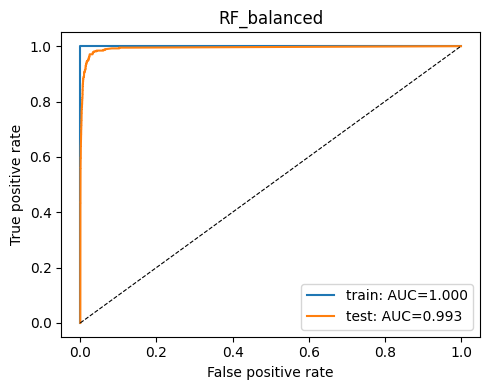

,model,split,error,AUC,TN,FP,FN,TP
0,RF_balanced,train,0.000083,1.000000,58995,5,0,1000
1,RF_balanced,test,0.009813,0.993231,15602,23,134,241


Balanced OOB error: 0.0071666666666666545 held-out test error: 0.009812500000000002


,model,split,error,AUC,TN,FP,FN,TP
0,RF_plain,train,0.001083,0.999991,59000,0,65,935
1,RF_plain,test,0.008375,0.994188,15607,18,116,259
2,RF_balanced,train,0.000083,1.000000,58995,5,0,1000
3,RF_balanced,test,0.009813,0.993231,15602,23,134,241


In [6]:
rf_bal = RandomForestClassifier(n_estimators=100, min_samples_leaf=2, oob_score=True,
                                class_weight='balanced_subsample', random_state=SEED, n_jobs=-1)
rf_bal.fit(X_train, y_train)
rf_bal_metrics = evaluate('RF_balanced', rf_bal, X_train, X_test)
print('Balanced OOB error:', 1-rf_bal.oob_score_,
      'held-out test error:', rf_bal_metrics.iloc[1].error)
display(pd.concat([rf_plain_metrics, rf_bal_metrics], ignore_index=True))

## 1(e–f). L1-regularized XGBoost, cross-validation and SMOTE

XGBoost's `reg_alpha` penalizes **tree leaf weights**; it does not literally fit an L1 logistic regression at each node. The binary logistic objective supplies class probabilities. I select `reg_alpha` by five-fold stratified CV, compare mean validation error with test error, and report train/test confusion matrices and ROC/AUC. For SMOTE, each fold's imputer, log transform, scaler and synthetic samples are fitted/generated **only from that fold's training partition**. The validation fold and test set remain untouched. This prevents synthetic copies or learned preprocessing from leaking into evaluation.

SMOTE: False CV errors: {0.1: 0.006500000000000017, 1.0: 0.006566666666666676, 10.0: 0.007416666666666671} selected alpha: 0.1


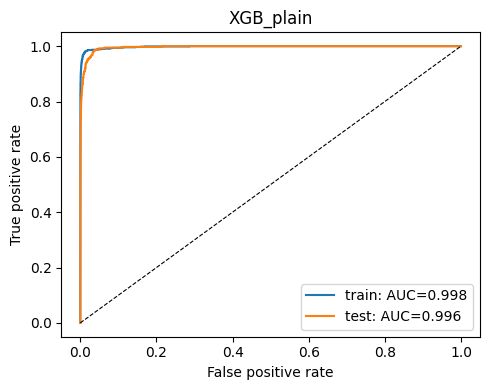

,model,split,error,AUC,TN,FP,FN,TP
0,XGB_plain,train,0.002883,0.998017,58971,29,144,856
1,XGB_plain,test,0.007188,0.996161,15604,21,94,281


Five-fold CV error: 0.006500000000000017 test error: 0.007187500000000013


In [7]:
# A compact implementation of ordinary SMOTE to keep the notebook self-contained.
def smote(x, y, seed=SEED, k=5):
    rng = np.random.default_rng(seed)
    minority = x[y == 1]
    majority_n = int((y == 0).sum())
    needed = majority_n - len(minority)
    if needed <= 0: return x, y
    neighbors = NearestNeighbors(n_neighbors=min(k+1, len(minority)), n_jobs=-1).fit(minority)
    ids = neighbors.kneighbors(minority, return_distance=False)[:, 1:]
    source = rng.integers(0, len(minority), needed)
    target = ids[source, rng.integers(0, ids.shape[1], needed)]
    lam = rng.random((needed, 1), dtype=np.float32)
    synthetic = minority[source] + lam * (minority[target] - minority[source])
    return np.vstack([x, synthetic]), np.r_[y, np.ones(needed, dtype=y.dtype)]

def prep_fold(train_idx, val_idx, use_smote):
    imp = SimpleImputer(strategy='median', keep_empty_features=True)
    a = imp.fit_transform(X_train_raw.iloc[train_idx]).astype('float32')
    b = imp.transform(X_train_raw.iloc[val_idx]).astype('float32')
    if use_smote:
        a = np.log1p(np.maximum(a, 0)); b = np.log1p(np.maximum(b, 0))
        scaler = StandardScaler()
        a = scaler.fit_transform(a).astype('float32')
        b = scaler.transform(b).astype('float32')
        a, ya = smote(a, y_train[train_idx], seed=SEED + int(train_idx[0]))
    else:
        ya = y_train[train_idx]
    return a, b, ya

from xgboost import XGBClassifier
def make_xgb(alpha):
    return XGBClassifier(n_estimators=100, max_depth=4, learning_rate=.1,
                         subsample=.8, colsample_bytree=.8, reg_alpha=alpha,
                         objective='binary:logistic', eval_metric='logloss',
                         tree_method='hist', n_jobs=4, random_state=SEED)

folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X_train_raw, y_train))
alphas = [0.1, 1, 10]

def tune_xgb(use_smote):
    scores = []
    # Reuse fold preprocessing across alpha values.
    prepared = [prep_fold(tr, va, use_smote) for tr, va in folds]
    for alpha in alphas:
        for fold, ((tr, va), (a, b, ya)) in enumerate(zip(folds, prepared), 1):
            model = make_xgb(alpha).fit(a, ya)
            scores.append(dict(alpha=alpha, fold=fold, validation_error=
                               1-accuracy_score(y_train[va], model.predict(b))))
    table = pd.DataFrame(scores)
    means = table.groupby('alpha').validation_error.mean()
    best = float(means.idxmin())
    print('SMOTE:', use_smote, 'CV errors:', means.to_dict(), 'selected alpha:', best)
    return best, table

alpha_plain, cv_plain = tune_xgb(False)
cv_plain.to_csv(RESULTS / 'xgb_plain_cv.csv', index=False)
xgb_plain = make_xgb(alpha_plain).fit(X_train, y_train)
xgb_plain_metrics = evaluate('XGB_plain', xgb_plain, X_train, X_test)
print('Five-fold CV error:', cv_plain.groupby('alpha').validation_error.mean().loc[alpha_plain],
      'test error:', xgb_plain_metrics.iloc[1].error)

SMOTE: True CV errors: {0.1: 0.01633333333333333, 1.0: 0.01605000000000001, 10.0: 0.017233333333333344} selected alpha: 1.0
After SMOTE: [59000 59000]


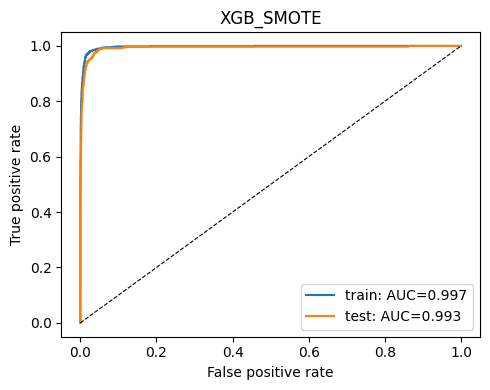

,model,split,error,AUC,TN,FP,FN,TP
0,XGB_SMOTE,train,0.013783,0.996683,58216,784,43,957
1,XGB_SMOTE,test,0.015375,0.993183,15411,214,32,343


Five-fold CV error: 0.01605000000000001 test error: 0.015375000000000028


,model,split,error,AUC,TN,FP,FN,TP
5,XGB_plain,test,0.007188,0.996161,15604,21,94,281
1,RF_plain,test,0.008375,0.994188,15607,18,116,259
3,RF_balanced,test,0.009813,0.993231,15602,23,134,241
7,XGB_SMOTE,test,0.015375,0.993183,15411,214,32,343


In [8]:
alpha_smote, cv_smote = tune_xgb(True)
cv_smote.to_csv(RESULTS / 'xgb_smote_cv.csv', index=False)
log_train = np.log1p(np.maximum(X_train, 0))
log_test = np.log1p(np.maximum(X_test, 0))
scaler = StandardScaler()
S_train = scaler.fit_transform(log_train).astype('float32')
S_test = scaler.transform(log_test).astype('float32')
S_train_smote, y_smote = smote(S_train, y_train)
print('After SMOTE:', np.bincount(y_smote))
xgb_smote = make_xgb(alpha_smote).fit(S_train_smote, y_smote)
xgb_smote_metrics = evaluate('XGB_SMOTE', xgb_smote, S_train, S_test)
print('Five-fold CV error:', cv_smote.groupby('alpha').validation_error.mean().loc[alpha_smote],
      'test error:', xgb_smote_metrics.iloc[1].error)
comparison = pd.concat([rf_plain_metrics, rf_bal_metrics, xgb_plain_metrics,
                        xgb_smote_metrics], ignore_index=True)
comparison.to_csv(RESULTS / 'model_comparison.csv', index=False)
display(comparison[comparison.split=='test'].sort_values('error'))

## Results and comparison

The unweighted forest has OOB error **0.00645** versus held-out error **0.00838**; the weighted forest has OOB error **0.00717** versus test error **0.00981**. The latter did not help this sample at the default 0.5 threshold: positive-class recall fell from **259/375 (69.1%)** to **241/375 (64.3%)**. Class weighting changes fitting costs but does not guarantee a better threshold-dependent result.

The selected XGBoost L1 penalties are **0.1** without SMOTE and **1** with SMOTE. Five-fold validation errors are **0.00650** and **0.01605** respectively; held-out errors are **0.00719** and **0.01538**. SMOTE increased positive-class recall from **281/375 (74.9%)** to **343/375 (91.5%)**, while false positives rose from **21** to **214**. Thus SMOTE improves minority detection but worsens overall accuracy at the default threshold. The untouched test AUCs are **0.9962** and **0.9932**. These comparisons use the same original 16,000-row test set.

## 2. ISLR 6.6.3 — Lasso constraint

Let \(s\) increase from zero in \(\sum_j |\beta_j|\leq s\). The feasible sets are nested, so the **training RSS decreases** (choice iv; it may eventually plateau at the least-squares fit). The **test RSS typically decreases then increases** (ii), because removing too much shrinkage eventually raises variance. The **variance increases** (iii), the **squared bias decreases** (iv), and **irreducible error is constant** (v). These are expected bias–variance trends; particular test samples need not be perfectly U-shaped.

## 3. ISLR 6.6.5 — Ridge and lasso with identical predictors

Write \(x_{11}=x_{12}=a\), \(x_{21}=x_{22}=-a\), \(y_1=y\), \(y_2=-y\), and \(t=\beta_1+\beta_2\). The centered ridge objective is
\[
2(y-at)^2+\lambda(\beta_1^2+\beta_2^2).
\]
For a fixed \(t\), the penalty is minimized uniquely at \(\beta_1=\beta_2=t/2\). Differentiation gives \(t=4ay/(4a^2+\lambda)\), hence both coefficients equal \(2ay/(4a^2+\lambda)\).

The lasso objective is
\[
2(y-at)^2+\lambda(|\beta_1|+|\beta_2|).
\]
For a fixed sum \(t\), the smallest penalty is \(|t|\), achieved by **every split** with both coefficients having the sign of \(t\) (zeros allowed). Thus the optimum sum is \(t=\operatorname{sign}(ay)\max(4|ay|-\lambda,0)/(4a^2)\) when \(a\ne0\). If \(t\ne0\), all \((\beta_1,\beta_2)=(u,t-u)\) with \(u\) between 0 and \(t\) are solutions, demonstrating the nonuniqueness. If the penalty forces \(t=0\), the unique solution is both zero.

## 4. ISLR 8.4.5 — Combining bagged classification trees

The ten estimated probabilities of the **red** class are 0.10, 0.15, 0.20, 0.20, 0.55, 0.60, 0.60, 0.65, 0.70, and 0.75. At a threshold of 0.5, six trees vote red and four vote green, so **majority voting predicts red**.

The average red-class probability is (0.10 + 0.15 + 0.20 + 0.20 + 0.55 + 0.60 + 0.60 + 0.65 + 0.70 + 0.75) / 10 = **0.45**. Since 0.45 < 0.5, **averaging probabilities predicts green**. The methods disagree because a vote ignores how far each tree's probability is from the threshold, whereas the average retains those magnitudes.

## 5. ISLR 9.7.3 — Maximal margin classifier

The seven given points are red \((3,4),(2,2),(4,4),(1,4)\) and blue \((2,1),(4,3),(4,1)\). The optimal separator is \(X_2-X_1+0.5=0\). Classify as red when \(0.5-X_1+X_2>0\), blue otherwise; thus \((\beta_0,\beta_1,\beta_2)=(0.5,-1,1)\). The parallel supporting lines are \(X_2-X_1=0\) and \(X_2-X_1=-1\), with support vectors \((2,2),(4,4),(2,1),(4,3)\). The geometric margin from the separator to either supporting line is \(0.5/\sqrt2\). Point 7, \((4,1)\), lies well beyond the blue supporting line, so a small movement does not change the optimal separator. A separating but suboptimal alternative is \(X_2-X_1+0.25=0\). Adding a blue point at \((3,4)\), already occupied by a red point, makes linear separation impossible.

![Seven observations, optimal separator, margins, and a suboptimal separator](../results/islr_9_7_3.png)

## References
- [Official HW6 handout](https://www.dropbox.com/scl/fo/s9kozp911ukrsof3f6drc/AJN5T2UK9y9mOmcHrRXelm8/Homework6.pdf?rlkey=vja8fyqknbupazfn61on6v85j&dl=0) and its [official data folder](https://www.dropbox.com/scl/fo/s9kozp911ukrsof3f6drc/AHX54G-TWp7sGXCoh5h08WI/Homework%206%20Data?rlkey=vja8fyqknbupazfn61on6v85j&dl=0).
- [Scikit-learn imputation](https://scikit-learn.org/stable/modules/impute.html), [random forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html), [cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html).
- [XGBoost parameters](https://xgboost.readthedocs.io/en/stable/parameter.html); [SMOTE original paper](https://www.jair.org/index.php/jair/article/view/10302).
- [ISLR, second edition](https://www.statlearning.com/): Exercises 6.6.3, 6.6.5 and 9.7.3.
